# Drones Ukraine v2 : 4. Visualisations géospatiales et synthèse

Ce notebook rassemble les résultats des notebooks 1 à 3 sous forme de cartes interactives (Leaflet, via Folium) et d'une planche de synthèse.

Les cartes HTML sont enregistrées dans `cartes/` : il suffit de les ouvrir dans un navigateur (connexion internet nécessaire pour le fond de carte et les bibliothèques JavaScript). Chaque carte contient aussi les frontières Natural Earth, lisibles même sans fond de carte.

In [1]:
import sys
import warnings
from pathlib import Path

# Le notebook s'exécute depuis le dossier v2 (ou depuis la racine du dépôt).
RACINE_V2 = Path.cwd() if (Path.cwd() / "drone_v2").exists() else Path.cwd() / "v2"
sys.path.insert(0, str(RACINE_V2))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from drone_v2 import config, viz

viz.appliquer_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))
%matplotlib inline
import json

from sklearn.metrics import confusion_matrix

from drone_v2 import cartes, donnees
from drone_v2.geo import Theatre

tables = donnees.charger_tables()
pistes, echantillon, radars = tables["pistes"], tables["echantillon"], tables["radars"]
theatre = Theatre()
R = config.REFERENTIELS
sites_ru = pd.read_csv(R / "sites_lancement_russes_v2.csv")
zones_ua = pd.read_csv(R / "zones_lancement_ukrainiennes_v2.csv")
predictions = pd.read_csv(config.RAPPORTS / "predictions_test_v2.csv")
with open(config.RAPPORTS / "metriques_v2.json", encoding="utf-8") as f:
    metriques = json.load(f)
plots = donnees.charger_plots()
plots_test = plots[plots.piste_id.isin(set(predictions.piste_id))]
print(f"{len(echantillon.piste_id.unique())} pistes dans l'échantillon cartographique, "
      f"{len(predictions)} pistes de test")

720 pistes dans l'échantillon cartographique, 1862 pistes de test


## 1. Carte interactive des pistes radar

Un échantillon de pistes par modèle (60 au plus), une couche par rôle, colorées par origine. Un clic sur une piste affiche le modèle, le rôle, la durée observée et la fin du vol ; un clic sur un site de lancement russe affiche la source.

In [2]:
f = cartes.carte_trajectoires(theatre, echantillon, pistes, sites_ru, zones_ua, radars,
                             config.CARTES / "carte_trajectoires_v2.html")
print(Path(f).relative_to(RACINE_V2), f"{Path(f).stat().st_size / 1e6:.1f} Mo")

cartes/carte_trajectoires_v2.html 2.4 Mo


## 2. Carte des prédictions sur le jeu de test

Pistes des 30 derniers jours, jamais vues pendant l'apprentissage : les pistes bien classées prennent la couleur du rôle prédit, les erreurs apparaissent en rouge, plus épaisses. Un clic sur une piste affiche le rôle réel, le rôle prédit et la confiance du modèle.

In [3]:
pred = predictions.rename(columns={"role": "role_reel", "role_confiance": "confiance"})
f = cartes.carte_predictions(theatre, plots_test, pred, config.CARTES / "carte_predictions_test_v2.html")
print(Path(f).relative_to(RACINE_V2), f"{Path(f).stat().st_size / 1e6:.1f} Mo")

cartes/carte_predictions_test_v2.html 2.0 Mo


## 3. Animation d'un raid nocturne

Le plus grand raid russe du jeu de test, tel que le voit le réseau radar : chaque piste avance minute par minute avec une traînée de 20 minutes. Le curseur temporel en bas de la carte permet de rejouer la nuit.

In [4]:
raids = pistes[pistes.raid_id.str.endswith("_RU_RAID") & pistes.piste_id.isin(set(predictions.piste_id))]
raid = raids.groupby("raid_id").size().idxmax()
ids = set(raids.loc[raids.raid_id == raid, "piste_id"])
print(f"Raid {raid} : {len(ids)} pistes radar ({(raids.loc[raids.raid_id == raid].role == 'Leurre').mean():.0%} de leurres)")
f = cartes.carte_animation_raid(theatre, plots[plots.piste_id.isin(ids)], pistes,
                               config.CARTES / "animation_raid_v2.html")
print(Path(f).relative_to(RACINE_V2), f"{Path(f).stat().st_size / 1e6:.1f} Mo")

Raid J114_RU_RAID : 59 pistes radar (32% de leurres)


cartes/animation_raid_v2.html 0.4 Mo


## 4. Densité des détections par origine

In [5]:
f = cartes.carte_densite(theatre, echantillon, pistes, config.CARTES / "carte_densite_v2.html")
print(Path(f).relative_to(RACINE_V2), f"{Path(f).stat().st_size / 1e6:.1f} Mo")

cartes/carte_densite_v2.html 1.2 Mo


## 5. Planche de synthèse

Chiffres clés du jeu de test, carte des erreurs de rôle, matrice de confusion, comparaison des algorithmes et classification précoce.

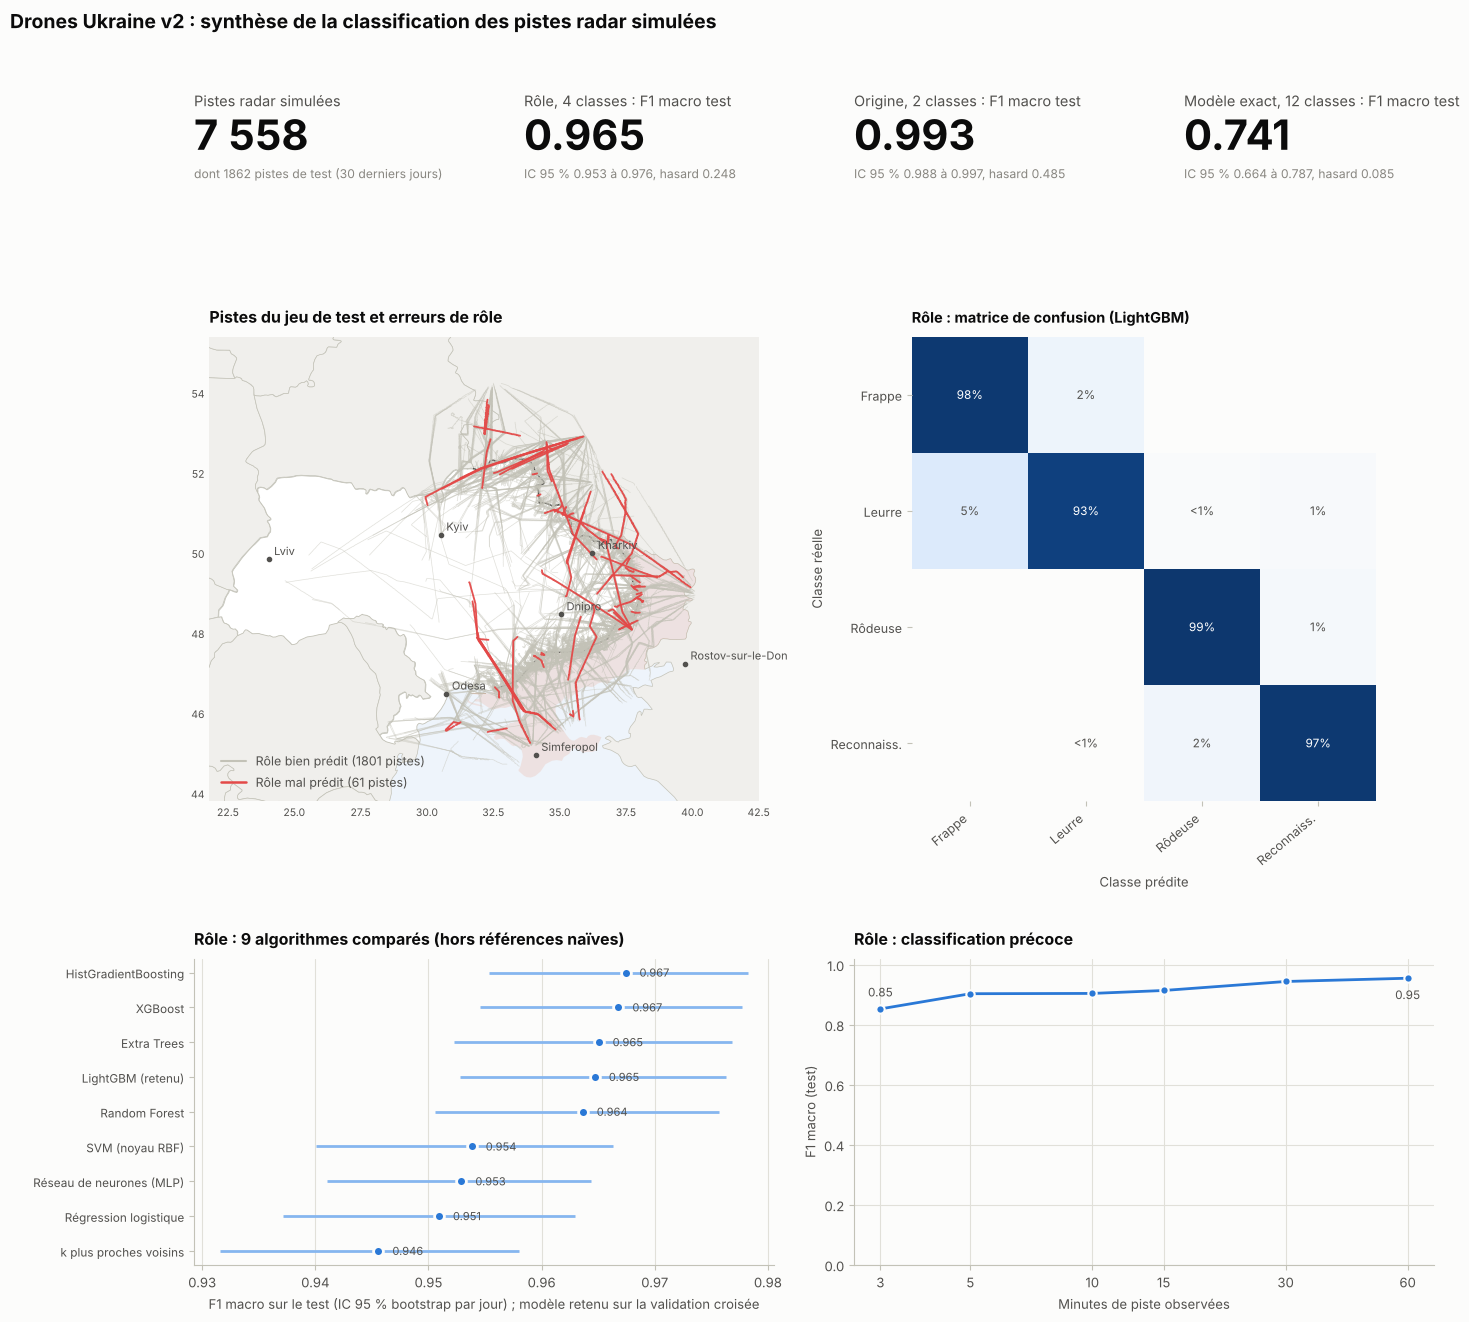

In [6]:
comparaison_role = pd.read_csv(config.RAPPORTS / "comparaison_modeles_role_v2.csv")
precoce = pd.DataFrame(metriques["classification_precoce"])
correct = pd.Series((predictions.role == predictions.role_predit).to_numpy(), index=predictions.piste_id)
classes = sorted(predictions.role.unique())
cm = confusion_matrix(predictions.role, predictions.role_predit, labels=classes)
fig = viz.fig_synthese(metriques, theatre, plots_test, correct, cm, classes, comparaison_role,
                       precoce[precoce.cible == "role"])
viz.sauver(fig, "40_synthese_v2")
plt.show()

## 6. Inventaire des sorties

In [7]:
lignes = []
for dossier in (config.CARTES, config.FIGURES):
    for f in sorted(dossier.iterdir()):
        if f.suffix in (".html", ".png"):
            lignes.append(dict(fichier=str(f.relative_to(RACINE_V2)), taille_ko=round(f.stat().st_size / 1e3)))
display(pd.DataFrame(lignes))

,fichier,taille_ko
0,cartes/animation_raid_v2.html,386
1,cartes/carte_densite_v2.html,1234
2,cartes/carte_groupes_v2.html,1865
3,cartes/carte_predictions_test_v2.html,1990
4,cartes/carte_trajectoires_v2.html,2422
5,cartes/pca_3d_v2.html,278
6,figures/01_theatre_v2.png,225
7,figures/02_trajectoires_par_role_v2.png,872
8,figures/03_zoom_front_tactique_v2.png,276
9,figures/04_profils_vol_v2.png,265
